# Quiz 8

Clustering a 2D dataset with known labels (quiz8-data.csv, columns X1, X2, Y): agglomerative clustering with 2 clusters (single and complete linkage) and its accuracy against Y; DBSCAN for eps 0.75 to 1.5 and k-means with 2 clusters, each plotted.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

data = pd.read_csv("./quiz8-data.csv")
target = data.loc[:, "Y"]
data = data.drop(["Y"], axis=1)

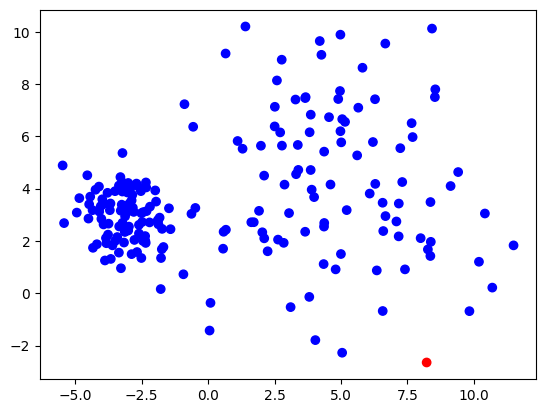

In [2]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram
clusteringS = AgglomerativeClustering(n_clusters=2, linkage="single").fit(data)
plt.scatter(data.X1, data.X2, c=clusteringS.labels_, cmap="bwr")
plt.show()

In [3]:
from sklearn.metrics import accuracy_score
print(accuracy_score(target,clusteringS.labels_))

0.495


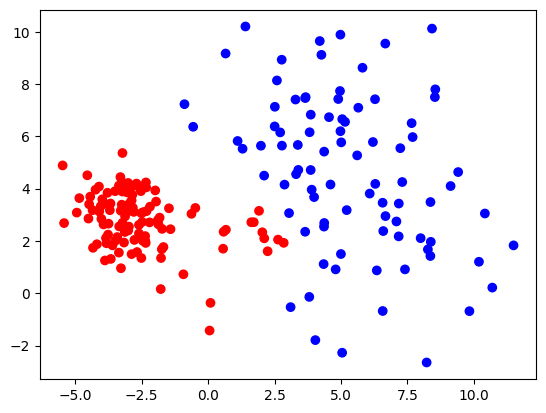

0.935


In [4]:
clusteringC = AgglomerativeClustering(n_clusters=2, linkage="complete").fit(data)
plt.scatter(data.X1, data.X2, c=clusteringC.labels_, cmap="bwr")
plt.show()
print(accuracy_score(target,clusteringC.labels_))

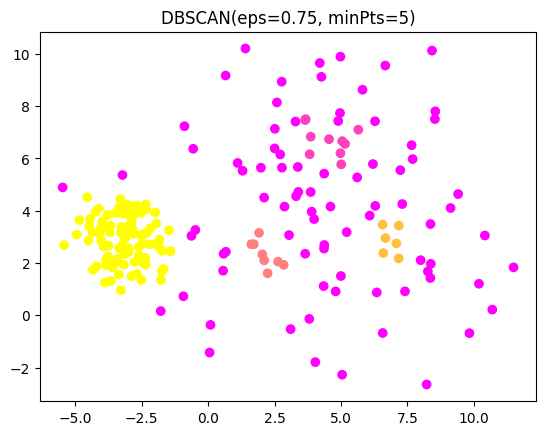

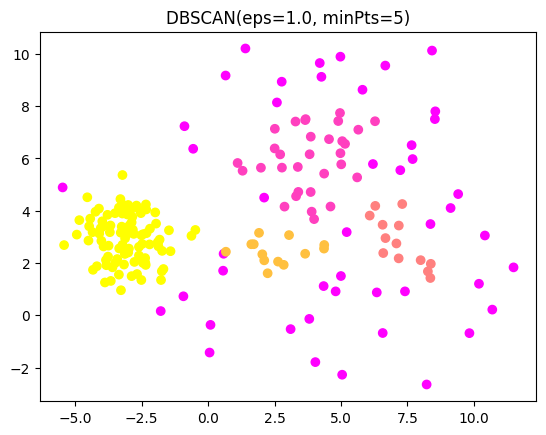

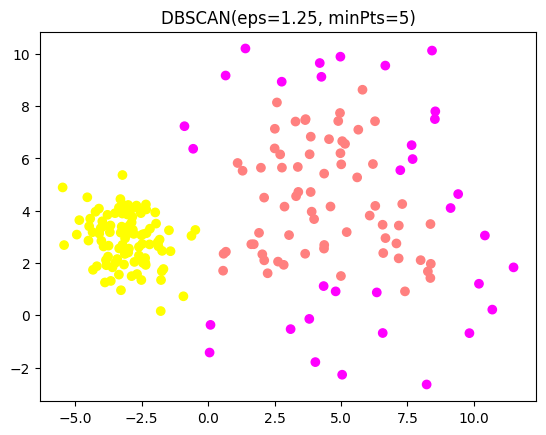

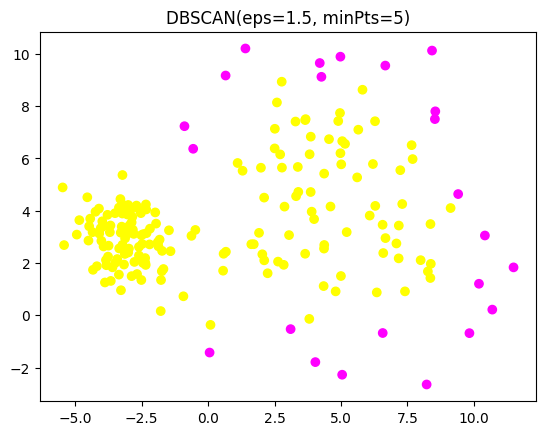

In [5]:
from sklearn.cluster import DBSCAN
eps_values = [0.75, 1.00, 1.25, 1.50]
for eps in eps_values:
    clustering = DBSCAN(eps=eps, min_samples=5).fit(data)
    clusters = clustering.labels_
    plt.scatter(data.X1, data.X2, c=clusters, cmap="spring")
    plt.title("DBSCAN(eps=" + str(eps) + ", minPts=5)")
    plt.show()
    

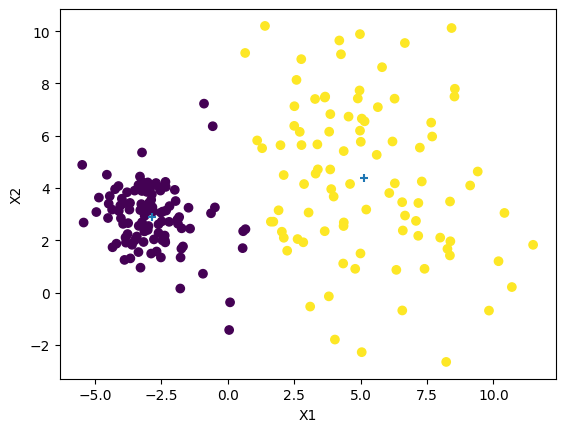

In [6]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=2, random_state=0).fit(data)
plt.scatter(data.X1, data.X2, c=kmeans.labels_)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], marker="+")
plt.xlabel("X1")
plt.ylabel("X2")
plt.show()